# Introduction to Pandas Series and DataFrames

**pandas** is the standard Python library for tabular data. A **DataFrame** is a table: columns with names and types, and rows with labels (the **index**). Each column is a **Series**. pandas reads files and databases, cleans and reshapes data, and feeds plots and models.

**After this lesson you can:**

1. Create Series and DataFrames, and explain the role of the index.
2. Read data from CSV, JSON and Parquet files.
3. Inspect a dataset: shape, dtypes, `info`, `describe`, `value_counts`.
4. Explain the main pandas 3 defaults: Copy-on-Write and the `str` dtype.

**Data:** Palmer penguins (344 penguins, CC0) and NYC taxi zones.

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent / "tools"))
import datasets                                   # course helper: downloads pinned public datasets

print("pandas", pd.__version__)

pandas 3.1.1


## 1. Series: a Labelled Column

A **Series** is a 1-D array of values with an **index** of labels. Operations between Series **align on the labels**, not on positions.

In [2]:
population_m = pd.Series({"Istanbul": 15.7, "Ankara": 5.8, "Izmir": 4.5}, name="population_m")
area_km2 = pd.Series({"Ankara": 25_632, "Istanbul": 5_461, "Bursa": 10_813}, name="area_km2")
print(population_m, "\n")
density = population_m * 1e6 / area_km2           # aligned by city name, not by position
print(density.round(0))

Istanbul    15.7
Ankara       5.8
Izmir        4.5
Name: population_m, dtype: float64 

Ankara       226.0
Bursa          NaN
Istanbul    2875.0
Izmir          NaN
dtype: float64


Istanbul and Ankara were matched by name although their positions differ. Izmir and Bursa appear in only one Series, so the result is `NaN` (missing). Alignment prevents silent mismatches, but it also creates missing values that you must handle.

## 2. DataFrame: a Table of Series

In [3]:
cities = pd.DataFrame({
    "city": ["Istanbul", "Ankara", "Izmir", "Bursa"],
    "population_m": [15.7, 5.8, 4.5, 3.2],
    "coastal": [True, False, True, True],
})
cities = cities.set_index("city")                  # use a column as the row labels
print(cities, "\n")
print("columns:", list(cities.columns), "| index:", list(cities.index), "| shape:", cities.shape)
print("one column is a Series:", type(cities["population_m"]).__name__)

          population_m  coastal
city                           
Istanbul          15.7     True
Ankara             5.8    False
Izmir              4.5     True
Bursa              3.2     True 

columns: ['population_m', 'coastal'] | index: ['Istanbul', 'Ankara', 'Izmir', 'Bursa'] | shape: (4, 2)
one column is a Series: Series


## 3. Read Files

| Format | Read | Write | Notes |
| :--- | :--- | :--- | :--- |
| CSV | `pd.read_csv` | `to_csv` | text, universal, no types |
| JSON | `pd.read_json`, `pd.json_normalize` | `to_json` | nested data |
| Parquet | `pd.read_parquet` | `to_parquet` | columnar, typed, compressed (M07 L08) |
| Excel | `pd.read_excel` | `to_excel` | needs `openpyxl` |
| SQL | `pd.read_sql` | `to_sql` | M07 L09 |

In [4]:
penguins = pd.read_json(datasets.fetch("penguins.json"))
zones = pd.read_csv(datasets.fetch("taxi_zone_lookup.csv"))
print("penguins:", penguins.shape, "| taxi zones:", zones.shape)
penguins.head()

penguins: (344, 7) | taxi zones: (265, 4)


,Species,Island,Beak Length (mm),Beak Depth (mm),Flipper Length (mm),Body Mass (g),Sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


## 4. Inspect a Dataset

Run the same checks on every new dataset: size, column types, missing values, value ranges and categories.

In [5]:
penguins.info()

<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Species              344 non-null    str    
 1   Island               344 non-null    str    
 2   Beak Length (mm)     342 non-null    float64
 3   Beak Depth (mm)      342 non-null    float64
 4   Flipper Length (mm)  342 non-null    float64
 5   Body Mass (g)        342 non-null    float64
 6   Sex                  334 non-null    str    
dtypes: float64(4), str(3)
memory usage: 24.9 KB


In [6]:
penguins.describe().round(1)

,Beak Length (mm),Beak Depth (mm),Flipper Length (mm),Body Mass (g)
count,342.0,342.0,342.0,342.0
mean,43.9,17.2,200.9,4201.8
std,5.5,2.0,14.1,802.0
min,32.1,13.1,172.0,2700.0
25%,39.2,15.6,190.0,3550.0
50%,44.4,17.3,197.0,4050.0
75%,48.5,18.7,213.0,4750.0
max,59.6,21.5,231.0,6300.0


In [7]:
print(penguins["Species"].value_counts(), "\n")
print(penguins["Sex"].value_counts(dropna=False), "\n")
print("missing values per column:\n", penguins.isna().sum())

Species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64 

Sex
MALE      168
FEMALE    165
NaN        10
.           1
Name: count, dtype: int64 

missing values per column:
 Species                 0
Island                  0
Beak Length (mm)        2
Beak Depth (mm)         2
Flipper Length (mm)     2
Body Mass (g)           2
Sex                    10
dtype: int64


`Sex` has missing values and possibly unusual codes; Lesson 08 cleans them. The text columns have the dtype `str`: since pandas 3.0, text uses a dedicated string type (backed by PyArrow when available) instead of the generic `object` type.

## 5. First Plots from a DataFrame

`DataFrame.plot` and `Series.plot` call matplotlib directly, which is enough for quick exploration.

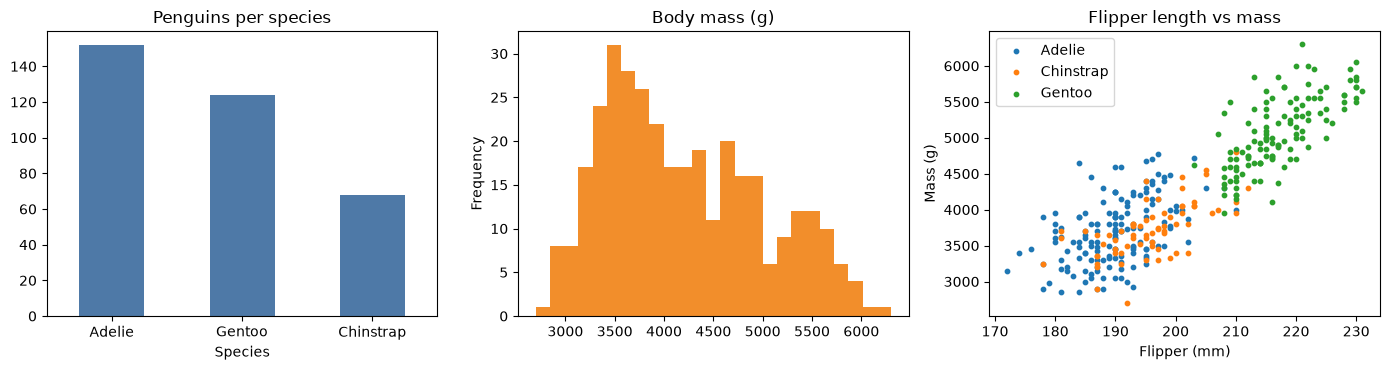

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
penguins["Species"].value_counts().plot.bar(ax=axes[0], color="#4E79A7", rot=0, title="Penguins per species")
penguins["Body Mass (g)"].plot.hist(ax=axes[1], bins=25, color="#F28E2B", title="Body mass (g)")
for species, part in penguins.groupby("Species"):
    axes[2].scatter(part["Flipper Length (mm)"], part["Body Mass (g)"], s=10, label=species)
axes[2].set(title="Flipper length vs mass", xlabel="Flipper (mm)", ylabel="Mass (g)")
axes[2].legend()
plt.tight_layout()
plt.show()

## 6. pandas 3 Defaults: Copy-on-Write

Since pandas 3.0, **Copy-on-Write (CoW)** is always on: every selection behaves like a copy, and pandas copies the data only when one of the objects is modified. Two consequences:

1. Changing a derived DataFrame never changes the original.
2. **Chained assignment** (`df[mask]["col"] = value`) never works. Use `df.loc[mask, "col"] = value`.

In [9]:
small = penguins[["Species", "Body Mass (g)"]].head(3)
subset = small[small["Species"] == "Adelie"]
subset.loc[subset.index[0], "Body Mass (g)"] = 0          # modify the derived frame
print("original unchanged:", small.iloc[0, 1])

small.loc[small["Species"] == "Adelie", "Body Mass (g)"] = 1   # the correct way to change the original
print("after .loc assignment:", small["Body Mass (g)"].tolist())

original unchanged: 3750.0
after .loc assignment: [1.0, 1.0, 1.0]


Lesson 15 covers pandas 3 (CoW, Arrow types) in depth.

*Insight: Inspect every new dataset with `shape`, `info()`, `describe()`, `isna().sum()` and `value_counts()` before any analysis. Most data problems (wrong types, missing values, odd categories) are visible in these five outputs.*

## Real-World Use Case or Analogy

A DataFrame is like a **spreadsheet with rules**: every column has one type, every row has a label, and calculations between two sheets match rows by label instead of by row number. That alignment is what makes pandas safe for joining data from different sources.

Analysts open almost every task with `read_csv`/`read_parquet`, `info()` and `describe()`. Data scientists use pandas to prepare training data; data engineers use it in small and medium pipelines before moving to Polars, DuckDB or Spark for larger volumes (Lessons 16–18, M13).